In [1]:
from typing import Annotated, Literal

from dotenv import load_dotenv
from langchain.mcp import MCPAdapter
from langchain_core.messages import AnyMessage, HumanMessage, SystemMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from pydantic import BaseModel, Field


/var/folders/mn/8mt68f1n2tl7s8y2nlzb6xvc0000gn/T/ipykernel_94874/2816453493.py:4: LangChainBetaWarning: `langchain.mcp` is in beta. It is actively being worked on, so the API may change.
  from langchain.mcp import MCPAdapter


In [2]:
load_dotenv()

True

In [3]:
model = ChatGoogleGenerativeAI(model="gemini-3.1-flash-lite")

In [4]:
# ---------------------------------------------------------------------------
# Boundary Schemas: Classification, ResearchFinding, ResearchSummary, FinalAnswer
# ---------------------------------------------------------------------------


class Classification(BaseModel):
    category: Literal["career", "relationships", "education", "health", "general"] = (
        Field(description="Defines category field of question asked by user")
    )


class ResearchFinding(BaseModel):
    source: str = Field(
        description="Source of the finding (e.g. 'vedic-astrology MCP server', 'rag-docs', or 'direct calculation')."
    )
    tool_name: str = Field(
        description="Name of the specific tool or retrieval source called (or 'none' if conceptual)."
    )
    facts: list[str] = Field(
        default_factory=list,
        description="Atomic, verified factual observations or calculations directly supported by the tool output.",
    )
    confidence: Literal["high", "medium", "low"] = Field(
        default="high",
        description="Confidence level in the finding based on calculation reliability and data completeness.",
    )
    uncertainty: str | None = Field(
        default=None,
        description="Known uncertainties, approximations, assumptions, or ambiguities in the data.",
    )
    limitations: list[str] = Field(
        default_factory=list,
        description="Known limitations or caveats (e.g. requires precise birth time, specific ayanamsa).",
    )


class ResearchSummary(BaseModel):
    findings: list[ResearchFinding] = Field(
        default_factory=list,
        description="Collection of validated research findings parsed from raw tool executions.",
    )
    overall_confidence: Literal["high", "medium", "low"] = Field(
        default="medium",
        description="Overall confidence in the aggregated research findings.",
    )
    summary: str = Field(
        description="Synthesized summary of all verified findings to guide the chat agent.",
    )
    limitations: list[str] = Field(
        default_factory=list,
        description="Global limitations or gaps identified across the research data.",
    )
    unresolved_questions: list[str] = Field(
        default_factory=list,
        description="Any questions, calculations, or data points that failed validation or could not be verified.",
    )


class FinalAnswer(BaseModel):
    concise_answer: str = Field(
        description="A direct, clear, and concise answer to the user's question based strictly on verified findings."
    )
    chart_evidence: list[str] = Field(
        default_factory=list,
        description="Astrological evidence or chart calculations supporting the answer (planets, houses, dashas, transits).",
    )
    practical_suggestions: list[str] = Field(
        default_factory=list,
        description="Actionable, grounded practical suggestions or constructive life guidance for the user.",
    )
    uncertainty_disclaimer: str = Field(
        default=(
            "Astrological interpretations reflect symbolic tendencies and potentials rather than deterministic guarantees."
        ),
        description="Uncertainty notes, boundary caveats, and ethical disclaimer.",
    )
    missing_input_request: str | None = Field(
        default=None,
        description="Request for missing birth profile details or clarifications needed for greater accuracy, or None if complete.",
    )

    def to_markdown(self) -> str:
        sections = [f"### Answer\n{self.concise_answer}"]
        if self.chart_evidence:
            sections.append(
                "### Chart Evidence\n"
                + "\n".join(f"- {item}" for item in self.chart_evidence)
            )
        if self.practical_suggestions:
            sections.append(
                "### Practical Suggestions\n"
                + "\n".join(f"- {item}" for item in self.practical_suggestions)
            )
        if self.missing_input_request:
            sections.append(
                f"### Missing Inputs / Clarifications\n{self.missing_input_request}"
            )
        if self.uncertainty_disclaimer:
            sections.append(f"### Note & Disclaimer\n*{self.uncertainty_disclaimer}*")
        return "\n\n".join(sections)

In [5]:
class ChatState(BaseModel):
    # The current user request; kept separate from tool-call messages.
    question: HumanMessage

    messages: Annotated[list[AnyMessage], add_messages] = Field(
        default_factory=list,
        description="Research-agent and tool-call messages for the current question",
    )
    category: str | None = "Unclassified"
    skill_instructions: str | None = "None"

    # Snapshot loaded from the authoritative user-profile database.
    user_id: str
    birth_profile_version: int
    dob: str
    birth_time: str
    birth_place: str

    research_findings: ResearchSummary | None = Field(
        default=None,
        description="Validated research findings and summary from MCP/RAG results",
    )
    final_answer: FinalAnswer | None = Field(
        default=None,
        description="Final structured output adhering to FinalAnswer schema",
    )

In [6]:
classifier_llm = model.with_structured_output(Classification)

CLASSIFIER_SYSTEM_PROMPT = """
    Classify the user's astrology question into exactly one category.

    Categories:

    career:
    Questions about jobs, career growth, promotion,
    business, professional success and career timing.

    relationships:
    Questions about marriage, love, spouse,
    compatibility and family relationships.

    education:
    Questions about studies, academic performance,
    higher education and educational prospects.

    health:
    Questions about health, illness and health-related
    astrological indications.

    general:
    Questions about birth charts, planetary positions,
    dashas, transits, yogas, doshas, astrology concepts,
    or anything that does not clearly belong to the other categories.

    If multiple categories are involved, select the primary
    subject of the user's question. Question: {question} """


def classify_node(state: ChatState):
    question = state.question.content
    print("Question", question)
    result = classifier_llm.invoke(CLASSIFIER_SYSTEM_PROMPT.format(question=question))

    return {"category": result.category}

In [7]:
from aistrology_langgraph_skeleton.skills.registry import load_skill


def load_skill_node(state: ChatState):
    skill = load_skill(state.category)
    return {"skill_instructions": skill}

In [8]:
mcpConfig = {
    "mcpServers": {
        "vedic-astrology": {
            "type": "sse",
            "url": "https://jagannatha-hora-359167915530.europe-west1.run.app/mcp",
            "headers": {"x-api-key": "demo"},
        }
    }
}

# Getting Tools
async with MCPAdapter(mcpConfig) as adapter:
    tools = await adapter.list_tools()
    # print(tools)

In [9]:
RESEARCH_SYSTEM_PROMPT = """
    You are AIstrology's research agent.

    Follow the domain-specific instructions below.

    {skill}

    User context:
    {user_context}

    Use tools when necessary to obtain accurate
    astrological calculations or retrieve knowledge.

    Return verified findings for the final-answer agent, rather than addressing
    the user directly.

    Never invent birth-chart calculations.
    """
llm_with_tools = model.bind_tools(tools)


def format_user_context(state: ChatState) -> str:
    return (
        f"user_id={state.user_id}\n"
        f"birth_profile_version={state.birth_profile_version}\n"
        f"dob={state.dob}\n"
        f"birth_time={state.birth_time}\n"
        f"birth_place={state.birth_place}"
    )


async def research_node(state: ChatState):
    prompt = RESEARCH_SYSTEM_PROMPT.format(
        skill=state.skill_instructions,
        user_context=format_user_context(state),
    )
    messages = [SystemMessage(content=prompt), state.question, *state.messages]

    response = await llm_with_tools.ainvoke(messages)

    return {"messages": [response]}

In [10]:
tool_node = ToolNode(tools)

In [11]:
def content_as_text(message: AnyMessage) -> str:
    if isinstance(message.content, str):
        return message.content
    if isinstance(message.content, list):
        return "\n".join(
            block["text"]
            for block in message.content
            if isinstance(block, dict)
            and block.get("type") == "text"
            and isinstance(block.get("text"), str)
        )
    return ""


def normalize_tool_message(msg: AnyMessage) -> dict:
    """Validate and normalize a raw ToolMessage before it reaches the summary node.
    If a tool fails or produces malformed/error data, returns a controlled
    'could not verify this calculation' result.
    """
    tool_name = getattr(msg, "name", "unknown_tool")
    raw_content = content_as_text(msg).strip()
    status = getattr(msg, "status", "success")

    is_error = (
        status == "error" or not raw_content or "error" in raw_content.lower()[:80]
    )

    if is_error:
        normalized_content = (
            f"Calculation failed or returned invalid data: {raw_content or 'empty response'}. "
            f"Status: could not verify this calculation."
        )
        verified = False
    else:
        normalized_content = raw_content
        verified = True

    return {
        "tool_name": tool_name,
        "content": normalized_content,
        "verified": verified,
        "status": status,
    }


summary_llm = model.with_structured_output(ResearchSummary)

SUMMARY_SYSTEM_PROMPT = """You are AIstrology's research summarization and validation node.
Your task is to convert raw tool executions, MCP/RAG responses, and research messages into validated ResearchFindings and a cohesive ResearchSummary.

Rules:
1. For each tool execution, generate a ResearchFinding:
   - source: e.g. 'vedic-astrology MCP server', 'rag-docs', or 'direct analysis'
   - tool_name: exact tool name called (or 'none' if conceptual)
   - facts: extract atomic, verified astrological facts or calculation results directly supported by the data
   - confidence: 'high' if verified calculation, 'medium' if partial, 'low' if unverified or approximated
   - uncertainty: note any data ambiguities, missing parameters, or birth time sensitivity
   - limitations: list specific limitations or calculation boundaries
2. If validation indicates 'could not verify this calculation' or a tool failed, DO NOT invent data. Record it with 'low' confidence or under 'unresolved_questions' / 'limitations'.
3. If no tools were called (e.g. general question), synthesize a concise summary noting no chart calculations were executed, and leave findings empty.
4. Produce a synthesized overall 'summary' for the final chat agent.
"""


def summarize_findings_node(state: ChatState):
    raw_blocks = []
    for msg in state.messages:
        text = content_as_text(msg).strip()
        if hasattr(msg, "tool_calls") and msg.tool_calls:
            calls_str = ", ".join(
                f"{tc.get('name')}({tc.get('args')})" for tc in msg.tool_calls
            )
            raw_blocks.append(f"AI requested tool calls: {calls_str}")
            if text:
                raw_blocks.append(f"AI note: {text}")
        elif msg.type == "tool":
            normalized = normalize_tool_message(msg)
            raw_blocks.append(
                f"Tool [{normalized['tool_name']}] (status={normalized['status']}, verified={normalized['verified']}):\n"
                f"{normalized['content']}"
            )
        elif text:
            raw_blocks.append(f"{msg.type.capitalize()}: {text}")

    transcript = "\n\n".join(raw_blocks)
    if not transcript.strip():
        transcript = (
            "No research tool calls or messages were recorded for this question."
        )

    user_content = f"""User Context:
{format_user_context(state)}

User Question:
{state.question.content}

Skill Instructions:
{state.skill_instructions}

Research Transcript:
{transcript}"""

    summary: ResearchSummary = summary_llm.invoke(
        [
            SystemMessage(content=SUMMARY_SYSTEM_PROMPT),
            HumanMessage(content=user_content),
        ]
    )
    return {"research_findings": summary}


chat_llm = model.with_structured_output(FinalAnswer)

CHAT_SYSTEM_PROMPT = """You are AIstrology, an expert and compassionate Vedic astrology advisor.
Synthesize the verified research findings into a structured final response for the user according to the FinalAnswer schema.

User Context:
{user_context}

Verified Research Findings:
{research_findings}

Instructions:
1. concise_answer: A direct, clear, and compassionate answer to the user's question, strictly grounded in the verified findings.
2. chart_evidence: Specific chart calculations or astrological principles (planets, houses, dashas, transits, yogas) supporting the answer. Only cite verified facts from the research findings; NEVER invent chart placements.
3. practical_suggestions: Actionable, grounded advice, remedial suggestions, or constructive next steps.
4. uncertainty_disclaimer: Thoughtful disclaimer noting that astrology reflects symbolic tendencies and timing potentials rather than deterministic fate.
5. missing_input_request: If critical birth details or clarifications are needed for deeper analysis, state them; otherwise None.
"""


def chat_node(state: ChatState):
    if state.research_findings:
        findings_payload = state.research_findings.model_dump_json(indent=2)
    else:
        findings_payload = "No verified research findings available."

    prompt = CHAT_SYSTEM_PROMPT.format(
        user_context=format_user_context(state),
        research_findings=findings_payload,
    )

    response: FinalAnswer = chat_llm.invoke(
        [SystemMessage(content=prompt), state.question]
    )

    return {"final_answer": response}

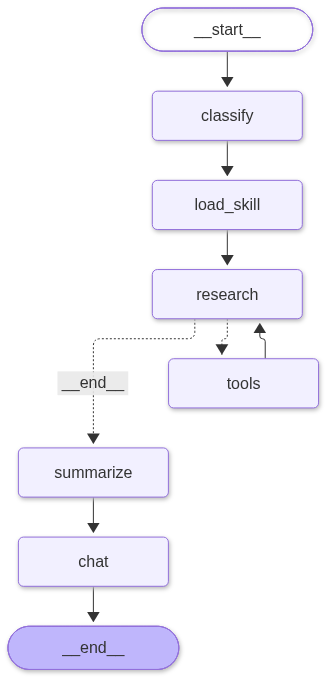

In [12]:
# Graph
graph = StateGraph(ChatState)
graph.add_node("chat", chat_node)
graph.add_node("classify", classify_node)
graph.add_node("load_skill", load_skill_node)
graph.add_node("tools", tool_node)
graph.add_node("research", research_node)
graph.add_node("summarize", summarize_findings_node)
graph.add_edge(START, "classify")
graph.add_edge("classify", "load_skill")
graph.add_edge("load_skill", "research")
graph.add_conditional_edges(
    "research",
    tools_condition,
    {
        "tools": "tools",
        END: "summarize",
    },
)
graph.add_edge("tools", "research")
# graph.add_conditional_edges(
#     "tools", tools_condition, {"research": "research", "summarize": "summarize"}
# )
graph.add_edge("summarize", "chat")
graph.add_edge("chat", END)

# Use a production checkpointer backed by your database in the application.
workflow = graph.compile(checkpointer=MemorySaver())
workflow

In [13]:
# Load this profile snapshot from your database; it remains authoritative.
birth_profile = {
    "user_id": "user_124",
    "birth_profile_version": 1,
    "dob": "2002-02-08",
    "birth_time": "16:10",
    "birth_place": "Jaipur, Rajasthan, India",
}
thread_id = (
    f"{birth_profile['user_id']}:birth-profile:{birth_profile['birth_profile_version']}"
)

result = await workflow.ainvoke(
    {
        "question": HumanMessage(
            content="I am in Software Engineering field, when will I get a good job?"
        ),
        **birth_profile,
    },
    config={
        "configurable": {"thread_id": thread_id},
    },
)

print("=== RESEARCH FINDINGS ===")
if result.get("research_findings"):
    print(result["research_findings"].model_dump_json(indent=2))

print("\n=== FINAL ANSWER ===")
if result.get("final_answer"):
    print(result["final_answer"].to_markdown())

Question I am in Software Engineering field, when will I get a good job?
=== RESEARCH FINDINGS ===
{
  "findings": [
    {
      "source": "vedic-astrology MCP server",
      "tool_name": "generate_horoscope",
      "facts": [
        "Ascendant is Gemini, Moon is in Sagittarius, Sun is in Capricorn.",
        "Mars is in the 10th house (Pisces) in the Rasi chart."
      ],
      "confidence": "high",
      "uncertainty": null,
      "limitations": [
        "Requires precise birth time for accurate house placements."
      ]
    },
    {
      "source": "vedic-astrology MCP server",
      "tool_name": "get_dasha",
      "facts": [
        "Currently in Sun Mahadasha (Sept 2022 – Sept 2028).",
        "Currently in Mercury Antardasha (July 2026 – May 2027)."
      ],
      "confidence": "high",
      "uncertainty": null,
      "limitations": [
        "Vimsottari Dasha timing is dependent on birth time accuracy."
      ]
    },
    {
      "source": "vedic-astrology MCP server",
      